#INFO 450 Project: IPR
##Team Members: Andrea Atoa Ortiz, Nahom Ghiorghis, Nathnael Abraham, Danny Truong
##Region: Texas

##Phase 1: Business Understanding
##Research Questions:
1. How reliable are Texas airports? Compare DFW, IAH, AUS, and SAT based on on-time arrival percentages and cancellation rates.
2. How concentrated are flight delays? Do a small number of routes account for most delay minutes?
3. When are flight delays worst? Examine delays by month, day of the week, and departure time.
4. Which airlines are the most and least reliable in Texas?

##Target Audience:
1. Travelers choosing between airports.
2. Airport authorities looking to improve flight reliability.
3. Corporate travel managers planning employee travel.

##Initial Expectations:
1. Larger airports may experience more total delays due to higher flight volumes.
2. Flight delays may increase during certain months and times of the day.
3. A small number of routes may account for a large portion of total delay minutes.



##Phase 2/3: Data Understanding/Preparation

(59820, 38)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59820 entries, 0 to 59819
Data columns (total 38 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Month                            59820 non-null  int64  
 1   DayOfWeek                        59820 non-null  int64  
 2   FlightDate                       59820 non-null  object 
 3   Reporting_Airline                59820 non-null  object 
 4   Tail_Number                      59673 non-null  object 
 5   Flight_Number_Reporting_Airline  59820 non-null  int64  
 6   Origin                           59820 non-null  object 
 7   Dest                             59820 non-null  object 
 8   CRSDepTime                       59820 non-null  int64  
 9   DepTime                          58585 non-null  float64
 10  DepDelay                         58582 non-null  float64
 11  DepDel15                         58582 non-null  float64
 12  TaxiOu

,Month,DayOfWeek,Flight_Number_Reporting_Airline,CRSDepTime,DepTime,DepDelay,DepDel15,TaxiOut,CRSArrTime,ArrTime,...,Distance,DistanceGroup,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay,DepHour,Weekend,DelayMinutes
count,59820.000000,59820.000000,59820.000000,59820.000000,58585.000000,58582.000000,58582.000000,58542.000000,59820.000000,58523.000000,...,59220.000000,59820.000000,14694.000000,14694.000000,14694.000000,14694.000000,14694.000000,59820.000000,59820.000000,58374.000000
mean,6.577767,3.998261,2499.750752,1370.490438,1381.582333,17.280752,0.259397,18.509378,1572.426814,1524.144388,...,862.159743,3.879037,23.295086,5.536001,12.107391,0.129645,32.527698,13.431361,0.277800,19.518913
std,3.393355,2.004825,1537.076010,481.479882,501.915603,61.148504,0.438308,9.070027,502.179528,550.754027,...,464.076808,1.824350,67.124487,36.805141,28.423038,6.464600,66.835879,4.786306,0.447918,59.622397
min,1.000000,1.000000,5.000000,500.000000,1.000000,-22.000000,0.000000,1.000000,1.000000,1.000000,...,90.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.000000,0.000000
25%,4.000000,2.000000,1355.750000,945.000000,947.000000,-5.000000,0.000000,13.000000,1151.000000,1126.000000,...,490.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,0.000000,0.000000
50%,7.000000,4.000000,2251.000000,1400.000000,1412.000000,-1.000000,0.000000,17.000000,1606.000000,1550.000000,...,868.000000,4.000000,5.000000,0.000000,0.000000,0.000000,10.000000,14.000000,0.000000,0.000000
75%,10.000000,6.000000,3473.500000,1810.000000,1825.000000,16.000000,1.000000,21.000000,2015.000000,2003.000000,...,1171.000000,5.000000,22.000000,0.000000,15.000000,0.000000,40.000000,18.000000,1.000000,15.000000
max,12.000000,7.000000,6539.000000,2359.000000,2400.000000,3475.000000,1.000000,167.000000,2359.000000,2400.000000,...,3904.000000,11.000000,1807.000000,1015.000000,800.000000,745.000000,2410.000000,23.000000,1.000000,3500.000000


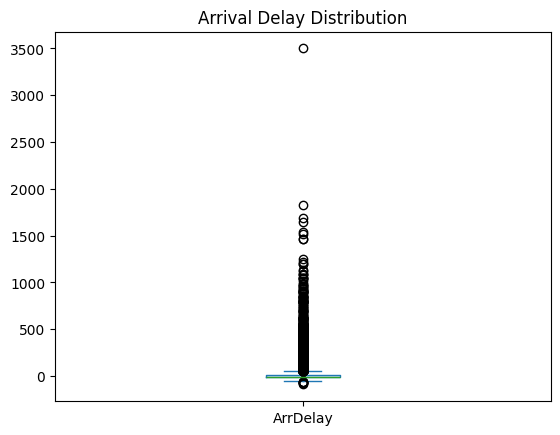

,Missing Count,Missing %
Tail_Number,147,0.25
DepTime,1235,2.06
DepDelay,1238,2.07
DepDel15,1238,2.07
TaxiOut,1278,2.14
ArrTime,1297,2.17
ArrDelay,1446,2.42
ArrDel15,1446,2.42
CancellationCode,58538,97.86
ActualElapsedTime,1446,2.42


Cancelled           0.0   1.0
CancellationCode             
False                 0  1282
True              58538     0
Cancelled    0.0        1.0
Diverted     0.0  1.0   0.0
ArrDelay                   
False      58374    0     0
True           0  164  1282
ArrDel15        0.0    1.0   NaN
CarrierDelay                    
False             0  14694     0
True          43680      0  1446


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv('flights_clean.csv') #load cleaned data

print(df.shape)
df.info()
display(df.describe())

df['ArrDelay'].plot(kind='box', title='Arrival Delay Distribution') #making boxplot to spot outliers
plt.show()

missing=pd.DataFrame({ #finding missing count/percent
    'Missing Count':df.isna().sum(),
    'Missing %':(df.isna().sum()/len(df)*100).round(2)
    })
display(missing[missing['Missing Count']>0])

#missing data evidence crosstabs
print(pd.crosstab(df['CancellationCode'].isna(), df['Cancelled']))
print(pd.crosstab(df['ArrDelay'].isna(), [df['Cancelled'], df['Diverted']]))
print(pd.crosstab(df['CarrierDelay'].isna(), df['ArrDel15'], dropna=False))


##Phase 4: Analysis


,mean,median
Origin,,
AUS,9.311251,-4.0
DFW,13.964746,-4.0
IAH,8.930092,-6.0
SAT,5.396702,-7.0


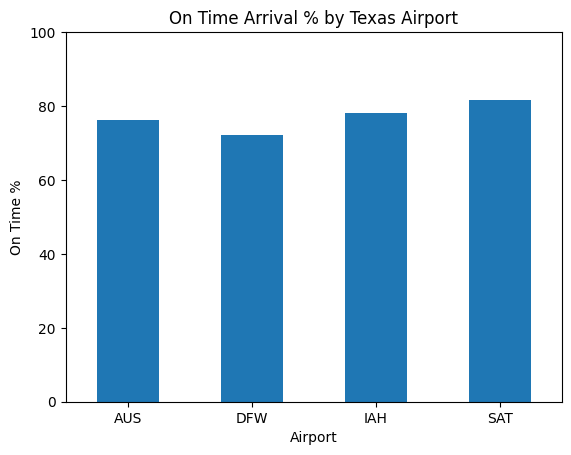

In [20]:
comp = df[(df['Cancelled']==0) & (df['Diverted']==0)] #only viewing completed flights

#Table: Mean and Median Arrival Delay by Texas Airport
delay_table= comp.groupby('Origin')['ArrDelay'].agg(['mean', 'median'])
display(delay_table)

#Chart: On Time Arrival % by Airport
ontime = 100-(comp.groupby('Origin')['ArrDel15'].mean()*100).round(2)
ontime.plot(kind='bar', title='On Time Arrival % by Texas Airport', ylabel='On Time %', xlabel='Airport',rot=0)
plt.ylim(0,100)
plt.show()

##Early Insights:
1. Mean and Median Arrival Delay by Airport: SAT has the lowest mean/median for arrival delays, while DFW has the highest.
2. On Time Arrival % by airports: SAT has the highest rate of on time arrivals for all of the Texan airports while DFW has the lowest.